In [1]:
# Google Drive mount karein
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os

# Apni zip file ka path yahan likhein (agar folder/naam alag hai toh change kar lena)
zip_path = '/content/drive/MyDrive/weedy-rice.zip'

# Colab ke local storage me extract karne ka path
extract_dir = '/content/dataset'

# Agar pehle se extract nahi hua hai toh extract karein
if not os.path.exists(extract_dir):
    print("Extracting zip file...")
    os.makedirs(extract_dir)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Extraction complete!")
else:
    print("Dataset already extracted.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset already extracted.


In [2]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Ab hamara data Google Colab ke local storage me hai
# Dhyan dein: Agar zip extract hone ke baad folder ka naam alag hai, toh ise adjust kar lein
WEEDY_DIR = Path('/content/dataset/WeedyRice-RGBMS-DB')

RGB_DIR = WEEDY_DIR / "RGB"
MASK_DIR = WEEDY_DIR / "Masks"

print("RGB folder:", RGB_DIR)
print("Mask folder:", MASK_DIR)
print("RGB images:", len(list(RGB_DIR.glob("*"))))
print("Masks:", len(list(MASK_DIR.glob("*.png"))))

RGB folder: /content/dataset/WeedyRice-RGBMS-DB/RGB
Mask folder: /content/dataset/WeedyRice-RGBMS-DB/Masks
RGB images: 734
Masks: 734


In [3]:
rgb_files = sorted(RGB_DIR.glob("*"))
mask_files = sorted(MASK_DIR.glob("*.png"))

sample_rgb = rgb_files[0]
sample_mask = MASK_DIR / f"{sample_rgb.stem}.png"

print("RGB:", sample_rgb.name)
print("Mask:", sample_mask.name)
print("Mask exists:", sample_mask.exists())

RGB: DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG
Mask: DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.png
Mask exists: True


In [4]:
image = cv2.imread(str(sample_rgb))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(str(sample_mask), cv2.IMREAD_GRAYSCALE)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask unique values:", sorted(set(mask.flatten())))

Image shape: (960, 1280, 3)
Mask shape: (960, 1280)
Mask unique values: [np.uint8(0), np.uint8(255)]


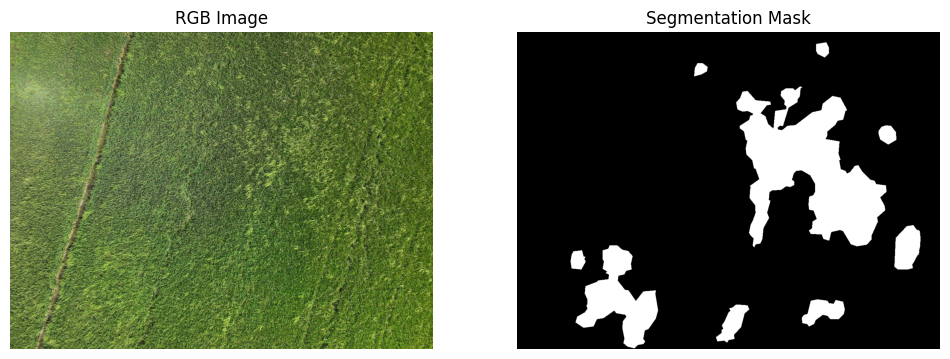

In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Segmentation Mask")
plt.axis("off")

plt.show()

In [6]:
TRAIN_FILE = WEEDY_DIR / "train_list.txt"
VAL_FILE = WEEDY_DIR / "val_list.txt"
TEST_FILE = WEEDY_DIR / "test_list.txt"

train_ids = [x.strip() for x in TRAIN_FILE.read_text().splitlines() if x.strip()]
val_ids = [x.strip() for x in VAL_FILE.read_text().splitlines() if x.strip()]
test_ids = [x.strip() for x in TEST_FILE.read_text().splitlines() if x.strip()]

print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))
print("Total:", len(train_ids) + len(val_ids) + len(test_ids))

Train: 438
Validation: 148
Test: 148
Total: 734


In [7]:
rgb_files = list(RGB_DIR.glob("*"))
rgb_names = {p.name for p in rgb_files}

train_missing = [x for x in train_ids if x not in rgb_names]
val_missing = [x for x in val_ids if x not in rgb_names]
test_missing = [x for x in test_ids if x not in rgb_names]

print("Missing train images:", len(train_missing))
print("Missing validation images:", len(val_missing))
print("Missing test images:", len(test_missing))

Missing train images: 0
Missing validation images: 0
Missing test images: 0


In [8]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

class RiceSegmentationDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        image_names,
        image_size=(320, 240),
        augment=False
    ):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.image_names = image_names
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):

        image_name = self.image_names[index]

        image_path = self.image_dir / image_name
        mask_path = self.mask_dir / Path(image_name).with_suffix(".png").name

        # Load image and mask
        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Resize
        image = image.resize(
            self.image_size,
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            self.image_size,
            Image.Resampling.NEAREST
        )

        # Convert to NumPy
        image = np.array(image)
        mask = np.array(mask)

        # -------------------------
        # Data Augmentation
        # -------------------------
        if self.augment:

            # Horizontal flip
            if np.random.rand() < 0.5:
                image = np.fliplr(image).copy()
                mask = np.fliplr(mask).copy()

            # Vertical flip
            if np.random.rand() < 0.5:
                image = np.flipud(image).copy()
                mask = np.flipud(mask).copy()

        # Image: HWC -> CHW
        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        image = image.permute(2, 0, 1)

        # Normalize image 0-255 → 0-1
        image = image / 255.0

        # Mask 0/255 → 0/1
        mask = torch.tensor(
            mask,
            dtype=torch.float32
        )

        mask = mask / 255.0

        return image, mask

In [9]:
train_dataset = RiceSegmentationDataset(
    RGB_DIR, MASK_DIR, train_ids, image_size=(320, 240), augment=True
)

val_dataset = RiceSegmentationDataset(
    RGB_DIR, MASK_DIR, val_ids, image_size=(320, 240), augment=False
)

test_dataset = RiceSegmentationDataset(
    RGB_DIR, MASK_DIR, test_ids, image_size=(320, 240), augment=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 438
Validation: 148
Test: 148


In [10]:
sample_image, sample_mask = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)

print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)

print("Image min:", sample_image.min().item())
print("Image max:", sample_image.max().item())

print("Mask unique values:", torch.unique(sample_mask))

Image shape: torch.Size([3, 240, 320])
Mask shape: torch.Size([240, 320])
Image dtype: torch.float32
Mask dtype: torch.float32
Image min: 0.03921568766236305
Image max: 0.7843137383460999
Mask unique values: tensor([0., 1.])


In [11]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 110
Validation batches: 37
Test batches: 37


In [12]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Images dtype:", images.dtype)
print("Masks dtype:", masks.dtype)

Images shape: torch.Size([4, 3, 240, 320])
Masks shape: torch.Size([4, 240, 320])
Images dtype: torch.float32
Masks dtype: torch.float32


In [13]:
import torch.nn as nn


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # Final segmentation layer
        self.final = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

print("Device:", device)
print(model)

Device: cuda
UNet(
  (enc1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(256, 512, 

In [15]:
# Get one batch
images, masks = next(iter(train_loader))

# Move to device
images = images.to(device)
masks = masks.to(device)

# Forward pass
outputs = model(images)

print("Input shape:", images.shape)
print("Target mask shape:", masks.shape)
print("Model output shape:", outputs.shape)

Input shape: torch.Size([4, 3, 240, 320])
Target mask shape: torch.Size([4, 240, 320])
Model output shape: torch.Size([4, 1, 240, 320])


In [16]:
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(outputs, targets, smooth=1e-7):

    probabilities = torch.sigmoid(outputs)

    probabilities = probabilities.view(probabilities.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (
        (2 * intersection + smooth)
        / (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
            + smooth
        )
    )

    return 1 - dice.mean()


def combined_loss(outputs, targets):

    bce = bce_loss(outputs, targets)

    dice = dice_loss(outputs, targets)

    return bce + dice
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", combined_loss)
print("Optimizer:", optimizer)

Loss function: <function combined_loss at 0x7dd6b2edd940>
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [17]:
import torch

def validate_model(model, val_loader, criterion, device):

    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                masks.unsqueeze(1)
            )

            val_loss += loss.item()

    val_loss = val_loss / len(val_loader)

    return val_loss

In [18]:
num_epochs = 20

best_val_loss = float("inf")

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()
    train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        loss = combined_loss(
            outputs,
            masks.unsqueeze(1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = combined_loss(
                outputs,
                masks.unsqueeze(1)
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    # -------------------------
    # Save best model
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "/content/best_unet.pth"
        )

        print("✅ Best model saved!")

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

✅ Best model saved!
Epoch [1/20] Train Loss: 1.3386 | Val Loss: 1.3472
✅ Best model saved!
Epoch [2/20] Train Loss: 1.3053 | Val Loss: 1.1411
✅ Best model saved!
Epoch [3/20] Train Loss: 1.1332 | Val Loss: 1.0218
✅ Best model saved!
Epoch [4/20] Train Loss: 1.0226 | Val Loss: 0.9383
✅ Best model saved!
Epoch [5/20] Train Loss: 0.8959 | Val Loss: 0.8307
✅ Best model saved!
Epoch [6/20] Train Loss: 0.7879 | Val Loss: 0.7037
Epoch [7/20] Train Loss: 0.8020 | Val Loss: 0.7095
Epoch [8/20] Train Loss: 0.7508 | Val Loss: 0.7590
✅ Best model saved!
Epoch [9/20] Train Loss: 0.7336 | Val Loss: 0.7004
✅ Best model saved!
Epoch [10/20] Train Loss: 0.7264 | Val Loss: 0.6529
✅ Best model saved!
Epoch [11/20] Train Loss: 0.7013 | Val Loss: 0.6388
✅ Best model saved!
Epoch [12/20] Train Loss: 0.6510 | Val Loss: 0.6242
✅ Best model saved!
Epoch [13/20] Train Loss: 0.6493 | Val Loss: 0.5995
✅ Best model saved!
Epoch [14/20] Train Loss: 0.6373 | Val Loss: 0.5870
✅ Best model saved!
Epoch [15/20] Train L

In [19]:
def calculate_metrics(model, loader, device, threshold=0.5):

    model.eval()

    total_dice = 0.0
    total_iou = 0.0
    total_samples = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            # Convert logits to probabilities
            probabilities = torch.sigmoid(outputs)

            # Convert probabilities to binary mask
            predictions = (probabilities > threshold).float()

            # Add channel dimension to masks
            masks = masks.unsqueeze(1)

            # Flatten
            predictions = predictions.view(predictions.size(0), -1)
            masks = masks.view(masks.size(0), -1)

            # Intersection
            intersection = (predictions * masks).sum(dim=1)

            # Dice Score
            dice = (
                (2 * intersection + 1e-7)
                / (predictions.sum(dim=1) + masks.sum(dim=1) + 1e-7)
            )

            # IoU
            union = (
                predictions.sum(dim=1)
                + masks.sum(dim=1)
                - intersection
            )

            iou = (
                (intersection + 1e-7)
                / (union + 1e-7)
            )

            total_dice += dice.sum().item()
            total_iou += iou.sum().item()
            total_samples += images.size(0)

    avg_dice = total_dice / total_samples
    avg_iou = total_iou / total_samples

    return avg_dice, avg_iou

In [20]:
dice_score, iou_score = calculate_metrics(
    model,
    val_loader,
    device
)

print(f"Dice Score: {dice_score:.4f}")
print(f"IoU Score:   {iou_score:.4f}")

Dice Score: 0.7710
IoU Score:   0.6488


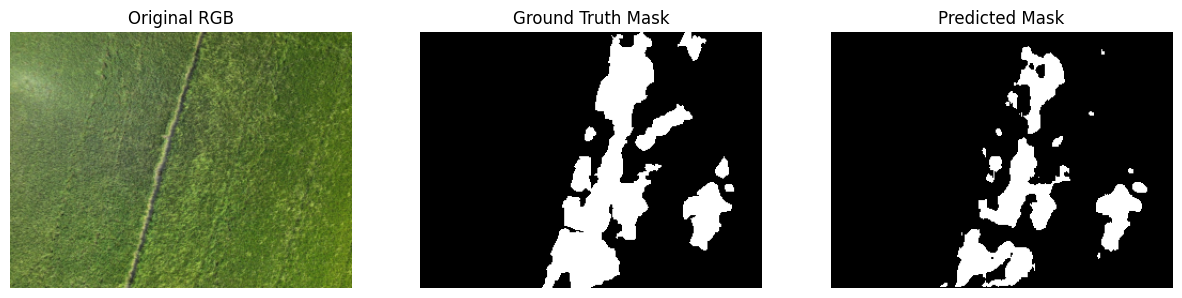

In [21]:
model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)
    probabilities = torch.sigmoid(outputs)
    predictions = (probabilities > 0.5).float()

# First image
image = images[0].cpu().permute(1, 2, 0).numpy()
true_mask = masks[0].cpu().numpy()
pred_mask = predictions[0, 0].cpu().numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(true_mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask, cmap="gray")
plt.title("Predicted Mask")
plt.axis("off")

plt.show()

In [22]:
# Best model load karo
model.load_state_dict(
    torch.load("/content/best_unet.pth", map_location=device)
)

model.eval()

dice_score = 0.0
iou_score = 0.0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        # Convert logits to probabilities
        predictions = torch.sigmoid(outputs)

        # Binary mask
        predictions = (predictions > 0.5).float()

        # Dice
        intersection = (predictions * masks.unsqueeze(1)).sum()
        dice = (
            (2 * intersection + 1e-7) /
            (predictions.sum() + masks.unsqueeze(1).sum() + 1e-7)
        )

        # IoU
        union = (
            predictions.sum()
            + masks.unsqueeze(1).sum()
            - intersection
        )

        iou = (intersection + 1e-7) / (union + 1e-7)

        dice_score += dice.item()
        iou_score += iou.item()

dice_score /= len(val_loader)
iou_score /= len(val_loader)

print(f"Validation Dice Score: {dice_score:.4f}")
print(f"Validation IoU Score: {iou_score:.4f}")

Validation Dice Score: 0.8070
Validation IoU Score: 0.6836


In [23]:
before_dice = 0.7874
before_iou = 0.6717

after_dice = dice_score
after_iou = iou_score

print("Segmentation Performance Comparison")
print("-" * 40)

print(f"Before Augmentation - Dice: {before_dice:.4f}")
print(f"After Augmentation  - Dice: {after_dice:.4f}")

print()

print(f"Before Augmentation - IoU : {before_iou:.4f}")
print(f"After Augmentation  - IoU : {after_iou:.4f}")

print()

print(f"Dice Improvement: {(after_dice - before_dice):.4f}")
print(f"IoU Improvement : {(after_iou - before_iou):.4f}")

Segmentation Performance Comparison
----------------------------------------
Before Augmentation - Dice: 0.7874
After Augmentation  - Dice: 0.8070

Before Augmentation - IoU : 0.6717
After Augmentation  - IoU : 0.6836

Dice Improvement: 0.0196
IoU Improvement : 0.0119


In [24]:
# Best augmented model load karo
model.load_state_dict(
    torch.load("/content/best_unet.pth", map_location=device)
)

model.eval()

test_dice = 0.0
test_iou = 0.0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        predictions = torch.sigmoid(outputs)
        predictions = (predictions > 0.5).float()

        # Dice
        intersection = (
            predictions * masks.unsqueeze(1)
        ).sum()

        dice = (
            (2 * intersection + 1e-7)
            /
            (
                predictions.sum()
                + masks.unsqueeze(1).sum()
                + 1e-7
            )
        )

        # IoU
        union = (
            predictions.sum()
            + masks.unsqueeze(1).sum()
            - intersection
        )

        iou = (
            (intersection + 1e-7)
            / (union + 1e-7)
        )

        test_dice += dice.item()
        test_iou += iou.item()

test_dice /= len(test_loader)
test_iou /= len(test_loader)

print(f"Final Test Dice Score: {test_dice:.4f}")
print(f"Final Test IoU Score: {test_iou:.4f}")

Final Test Dice Score: 0.8094
Final Test IoU Score: 0.6878


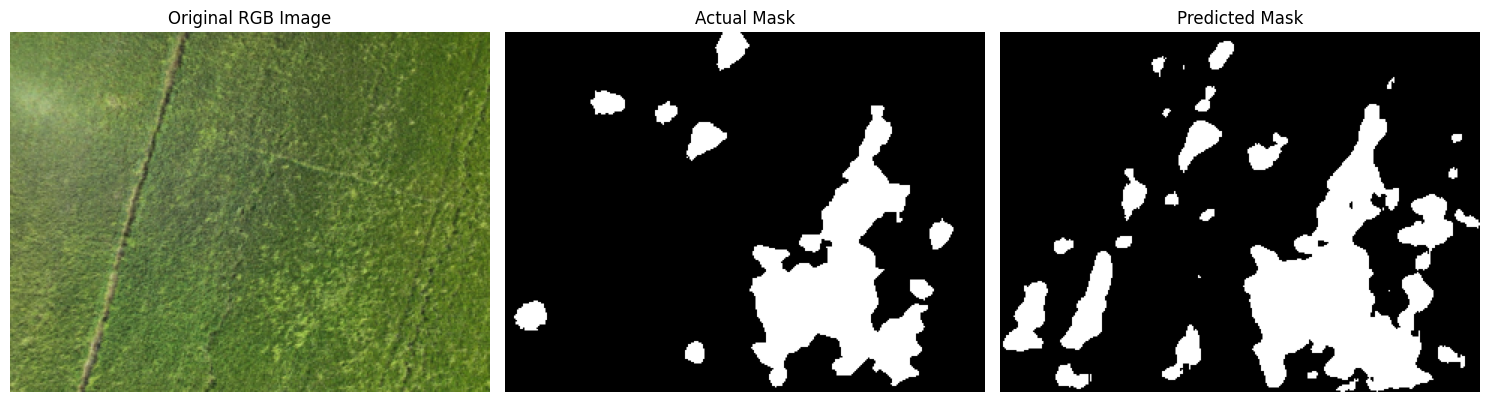

In [25]:
# Best model load karo
model.load_state_dict(
    torch.load("/content/best_unet.pth", map_location=device)
)

model.eval()

# Test set se ek sample
image, mask = test_dataset[0]

# Batch dimension add karo
input_image = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_image)
    prediction = torch.sigmoid(output)

# Binary prediction
prediction = (prediction > 0.5).float()

# CPU par lao
image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.numpy()
prediction_np = prediction.squeeze().cpu().numpy()

# Visualization
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_np, cmap="gray")
plt.title("Actual Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction_np, cmap="gray")
plt.title("Predicted Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

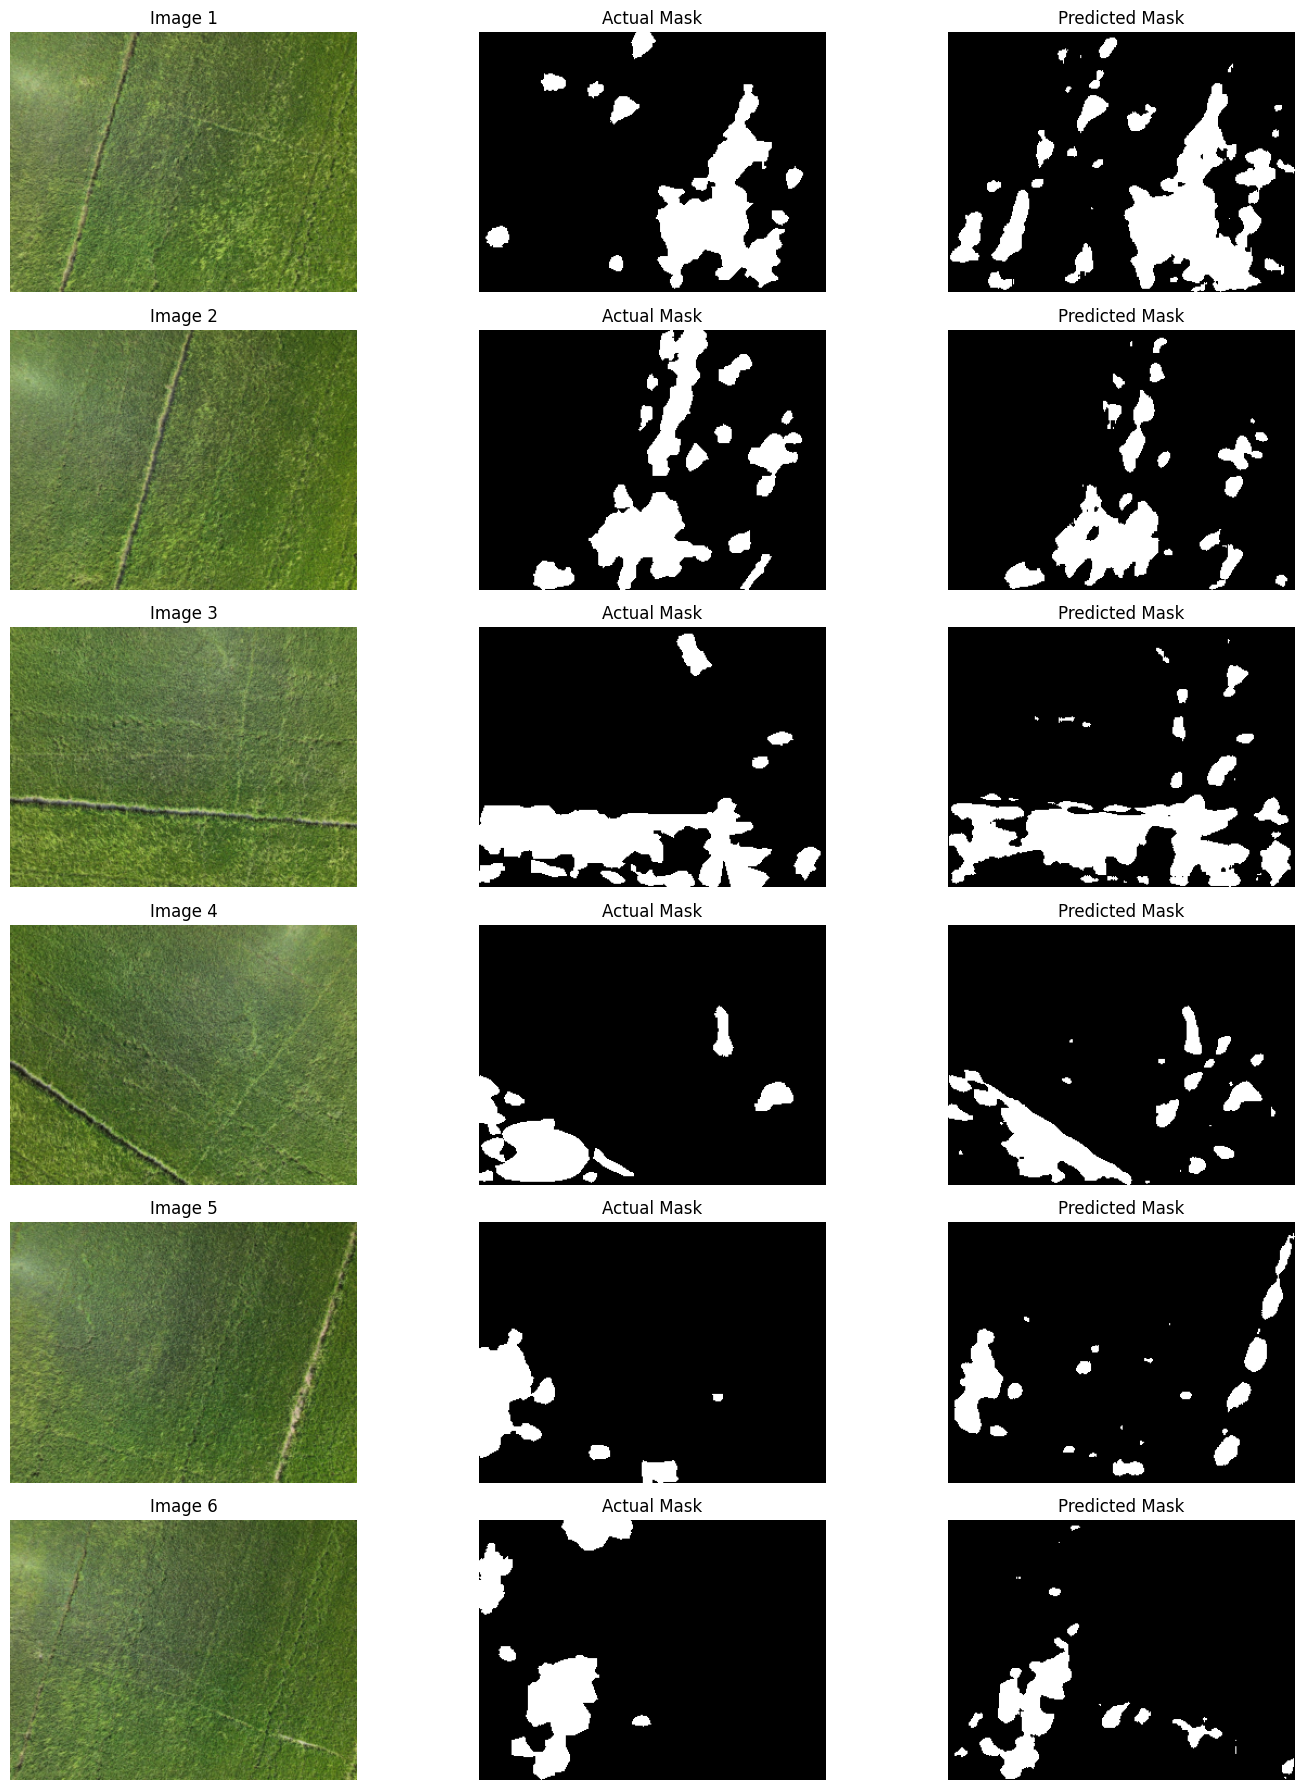

In [26]:
import matplotlib.pyplot as plt
import torch

model.eval()

num_samples = 6

plt.figure(figsize=(15, 18))

for i in range(num_samples):

    image, mask = test_dataset[i]

    input_image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_image)
        prediction = torch.sigmoid(output)
        prediction = (prediction > 0.5).float()

    image_np = image.permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    prediction_np = prediction.squeeze().cpu().numpy()

    # RGB
    plt.subplot(num_samples, 3, i * 3 + 1)
    plt.imshow(image_np)
    plt.title(f"Image {i+1}")
    plt.axis("off")

    # Actual mask
    plt.subplot(num_samples, 3, i * 3 + 2)
    plt.imshow(mask_np, cmap="gray")
    plt.title("Actual Mask")
    plt.axis("off")

    # Prediction
    plt.subplot(num_samples, 3, i * 3 + 3)
    plt.imshow(prediction_np, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# FINAL SEGMENTATION RESULTS
# ==========================================

before_dice = 0.7874
before_iou = 0.6717

augmented_val_dice = 0.8070
augmented_val_iou = 0.6836

final_test_dice = test_dice
final_test_iou = test_iou

print("=" * 50)
print("PaddyVision AI - Segmentation Results")
print("=" * 50)

print("\nModel: U-Net")
print("Input Size: 320 x 240")
print("Loss: BCE + Dice Loss")
print("Epochs: 20")
print("Augmentation: Horizontal + Vertical Flip")

print("\n--- Validation Performance ---")
print(f"Before Augmentation - Dice: {before_dice:.4f}")
print(f"After Augmentation  - Dice: {augmented_val_dice:.4f}")
print(f"Dice Improvement     : {augmented_val_dice - before_dice:.4f}")

print(f"\nBefore Augmentation - IoU: {before_iou:.4f}")
print(f"After Augmentation  - IoU: {augmented_val_iou:.4f}")
print(f"IoU Improvement     : {augmented_val_iou - before_iou:.4f}")

print("\n--- Final Test Performance ---")
print(f"Test Dice Score: {final_test_dice:.4f}")
print(f"Test IoU Score : {final_test_iou:.4f}")

print("\n" + "=" * 50)
print("Segmentation Pipeline Completed")
print("=" * 50)

PaddyVision AI - Segmentation Results

Model: U-Net
Input Size: 320 x 240
Loss: BCE + Dice Loss
Epochs: 20
Augmentation: Horizontal + Vertical Flip

--- Validation Performance ---
Before Augmentation - Dice: 0.7874
After Augmentation  - Dice: 0.8070
Dice Improvement     : 0.0196

Before Augmentation - IoU: 0.6717
After Augmentation  - IoU: 0.6836
IoU Improvement     : 0.0119

--- Final Test Performance ---
Test Dice Score: 0.8094
Test IoU Score : 0.6878

Segmentation Pipeline Completed
